# تمرین 1

In [ ]:
#reading data
from sklearn.datasets import fetch_california_housing 
import pandas as pd
housing = fetch_california_housing(as_frame=True) 
df = housing.frame 
X = df[["MedInc"]] 
y = df["MedHouseVal"]


as_frame makes the data into a pandas dataframe so it's easier to work on it using pandas

In [ ]:
#30 - 70 split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

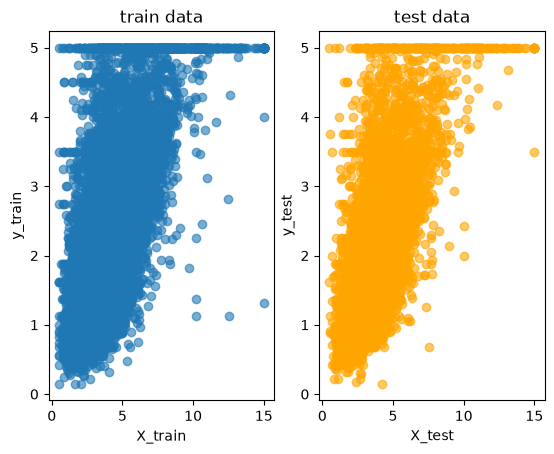

In [ ]:
#plotting scatters
import matplotlib.pyplot as plt
plt.subplot(1,2,1)
plt.scatter(X_train,y_train, alpha=0.6)
plt.title("train data")
plt.xlabel("X_train")
plt.ylabel("y_train")
plt.subplot(1,2,2)
plt.scatter(X_test,y_test, alpha=0.6, color = 'orange')
plt.title("test data")
plt.xlabel("X_test")
plt.ylabel("y_test")
plt.show()

In [ ]:
X_train.shape
#safe checking if x is 2d

(14448, 1)

In [ ]:
#training
from sklearn.linear_model import LinearRegression
lin1_model = LinearRegression()
lin1_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.42]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['MedInc']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.4479
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
#metrics calculation
from sklearn.metrics import r2_score
lin1_slope = lin1_model.coef_
lin1_intercept = lin1_model.intercept_
y_pred = lin1_model.predict(X_test)
lin1_r2 = r2_score(y_test, y_pred)
print("baseline:", lin1_intercept)
print("slope:", lin1_slope)
print("r2 score:", lin1_r2)

baseline: 0.4479496555604332
slope: [0.41819327]
r2 score: 0.47293192589970245


In [ ]:
def makeLinearModel(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3,
        random_state=42
    )
    model = LinearRegression()
    model.fit(X_train, y_train)

    slope = model.coef_
    intercept = model.intercept_

    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    
    print("baseline:", intercept)
    print("slope:", slope)
    print("r2 score:", r2)

X = df[["MedInc", "HouseAge", "AveRooms"]]
makeLinearModel(X, y)
# 4 percent improve

baseline: 0.013574378569972012
slope: [ 0.44191756  0.01683785 -0.02551413]
r2 score: 0.5126516784926669


# تمرین 2

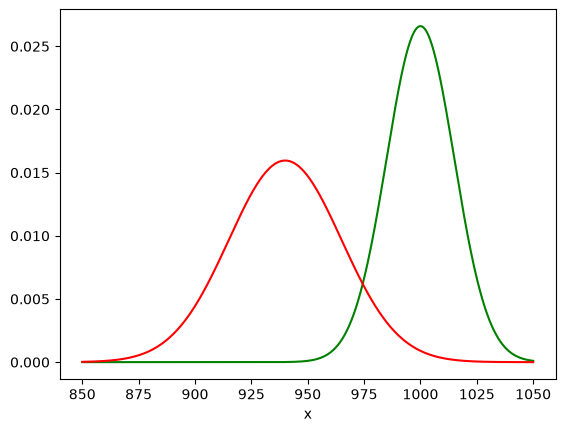

In [66]:
#الف
import scipy
import numpy as np
import matplotlib.pyplot as plt
P_healthy = 0.92
P_defective = 0.08
x = np.linspace(850, 1050, 1000)

dist_healthy = scipy.stats.norm(1000, 15)
dist_defective = scipy.stats.norm(940, 25)

lik_h = dist_healthy.pdf(x)
lik_d = dist_defective.pdf(x)

plt.plot(x, lik_h, color = 'green')
plt.plot(x, lik_d, color = 'red')
plt.xlabel('x')
plt.show()

these two pdfs are visibly overlapping

In [67]:
weight = 970
#detected as: healthy
num_h = (P_healthy * dist_healthy.pdf(weight))
num_d = P_defective * dist_defective.pdf(weight)
print("P(healthy)P(x|healthy):", num_h)
print("P(defective)P(x|defective):", num_d)
# bayes would say it's healthy too because
P_x = num_h + num_d 
post_h = num_h/P_x
post_d = num_d/P_x
print("Poterior healthy:", post_h)
print("Poterior defective:", post_d)
if post_h > post_d:
    print("\nbayes says healthy")
else:
    print("\nbayes says defective")

P(healthy)P(x|healthy): 0.003311445946142201
P(defective)P(x|defective): 0.0006213953759462815
Poterior healthy: 0.841998360712835
Poterior defective: 0.15800163928716499

bayes says healthy


In [88]:
# ب
import sklearn.datasets
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = sklearn.datasets.load_wine(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state=42,
    test_size= 0.3,
    stratify=y
)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

def trainModel(X, y, n):
    model = KNeighborsClassifier(n_neighbors=n)
    model.fit(X, y)
    return model

n5_knn_model = trainModel(X_train_scaled, y_train, 5)
n1_knn_model = trainModel(X_train_scaled, y_train, 1)
n15_knn_model = trainModel(X_train_scaled, y_train, 15)

X_test_scaled = scaler.transform(X_test)
n5_accuracy = accuracy_score(y_test, n5_knn_model.predict(X_test_scaled))
n1_accuracy = accuracy_score(y_test, n1_knn_model.predict(X_test_scaled))
n15_accuracy = accuracy_score(y_test, n15_knn_model.predict(X_test_scaled))

print("5 neighbors:", n5_accuracy)
print("1 neighbor:", n1_accuracy)
print("15 neighbors:", n15_accuracy)


5 neighbors: 0.9444444444444444
1 neighbor: 0.9629629629629629
15 neighbors: 0.9814814814814815


1 neighbor is overfit because comparing to 1 neighbor only could result in recording noise
15 neighbors could be underfit because model does not have enough data and could ignore local noise
5 neighbors must be a good generalization

In [91]:
print(X.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

Knn uses distances to determine and form clusters. If the features ranges differ greatly, this might affect the models view of the clusters negatively.
for example proline in this data set has larger numbers than other features in the dataset